# Part 1 - Global Localization (Perfect Situation)

Introduction to global and relative localization with noise analysis.

In [1]:
# Cell 2: Imports

import numpy as np
import matplotlib.pyplot as plt

from manifpy import SE2

import sys
sys.path.insert(0, '/workspace/Python/Relative-localisation-tutorial/src')

from config import TrajectoryConfig, NoiseConfig
from trajectory import generate_trajectory, sgal3_to_se2_poses, add_noise
from relative_pose import poses_to_se2, compute_relative_pose

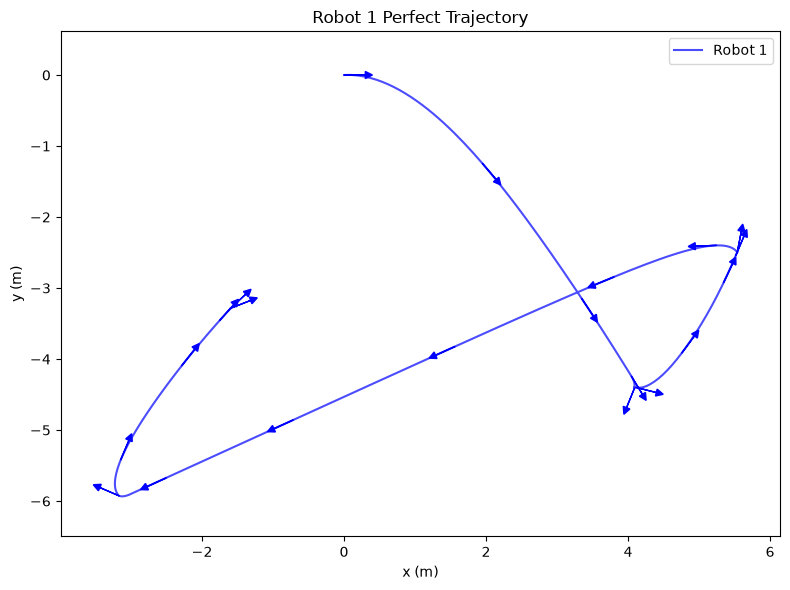

In [2]:
# Cell 3: Robot 1 perfect trajectory generation and visualization

traj_config = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)

traj_robot1 = generate_trajectory(
    duration=traj_config.duration,
    timestep=traj_config.timestep,
    seed=traj_config.seed
)

poses_robot1 = sgal3_to_se2_poses(traj_robot1.X_RRi)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(poses_robot1[:, 0], poses_robot1[:, 1], 'b-', label='Robot 1', alpha=0.7)

arrow_len = 0.3
step = max(1, len(poses_robot1) // 20)
for i in range(0, len(poses_robot1), step):
    x_i, y_i, theta_i = poses_robot1[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='b', ec='b')

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.axis('equal')
ax.legend()
ax.set_title('Robot 1 Perfect Trajectory')

plt.tight_layout()
plt.show()

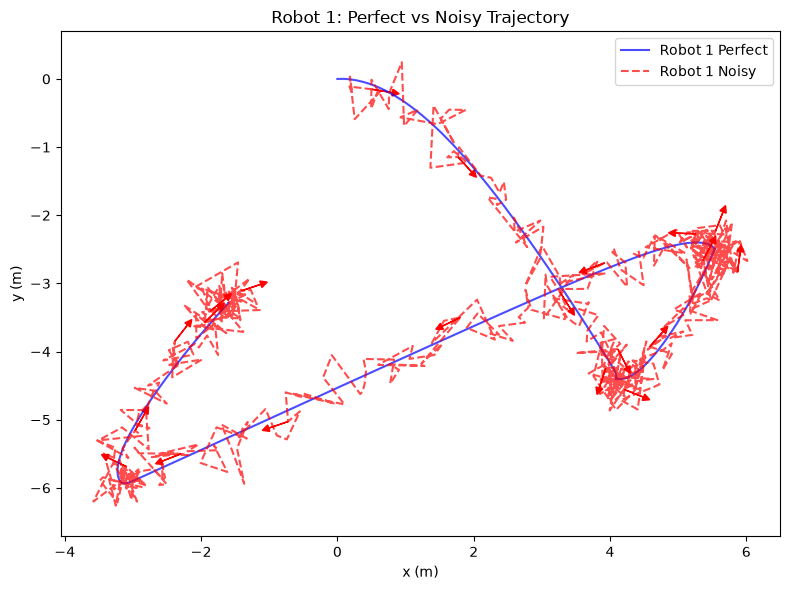

In [3]:
# Cell 4: Robot 1 noisy trajectory

noise_config = NoiseConfig(sigma_x=0.2, sigma_y=0.2, sigma_theta=np.deg2rad(5))

poses_robot1_noisy = add_noise(poses_robot1,
                                sigma_x=noise_config.sigma_x,
                                sigma_y=noise_config.sigma_y,
                                sigma_theta=noise_config.sigma_theta)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(poses_robot1[:, 0], poses_robot1[:, 1], 'b-', label='Robot 1 Perfect', alpha=0.7)
ax.plot(poses_robot1_noisy[:, 0], poses_robot1_noisy[:, 1], 'r--', label='Robot 1 Noisy', alpha=0.7)

step = max(1, len(poses_robot1_noisy) // 20)
for i in range(0, len(poses_robot1_noisy), step):
    x_i, y_i, theta_i = poses_robot1_noisy[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='r', ec='r')

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.axis('equal')
ax.legend()
ax.set_title('Robot 1: Perfect vs Noisy Trajectory')

plt.tight_layout()
plt.show()

# Cell 5: Analysis of noise effect on global pose estimation

In [5]:
# Cell 6: Robot 2 trajectory and relative pose computation (perfect)

traj_robot2 = generate_trajectory(
    duration=traj_config.duration,
    timestep=traj_config.timestep,
    seed=123
)

poses_robot2 = sgal3_to_se2_poses(traj_robot2.X_RRi)

se2_robot1 = poses_to_se2(poses_robot1)
se2_robot2 = poses_to_se2(poses_robot2)

relative_poses = np.zeros_like(poses_robot1)
for i in range(len(se2_robot1)):
    T_rel = compute_relative_pose(se2_robot1[i], se2_robot2[i])
    relative_poses[i, 0] = T_rel.x()
    relative_poses[i, 1] = T_rel.y()
    relative_poses[i, 2] = T_rel.angle()

# Cell 7: Theory - Perfect case

In [6]:
# Cell 8: Robot 2 noisy and relative pose computation (noisy)

poses_robot2_noisy = add_noise(poses_robot2,
                                sigma_x=noise_config.sigma_x,
                                sigma_y=noise_config.sigma_y,
                                sigma_theta=noise_config.sigma_theta)

se2_robot1_noisy = poses_to_se2(poses_robot1_noisy)
se2_robot2_noisy = poses_to_se2(poses_robot2_noisy)

relative_poses_noisy = np.zeros_like(poses_robot1)
for i in range(len(se2_robot1_noisy)):
    T_rel = compute_relative_pose(se2_robot1_noisy[i], se2_robot2_noisy[i])
    relative_poses_noisy[i, 0] = T_rel.x()
    relative_poses_noisy[i, 1] = T_rel.y()
    relative_poses_noisy[i, 2] = T_rel.angle()

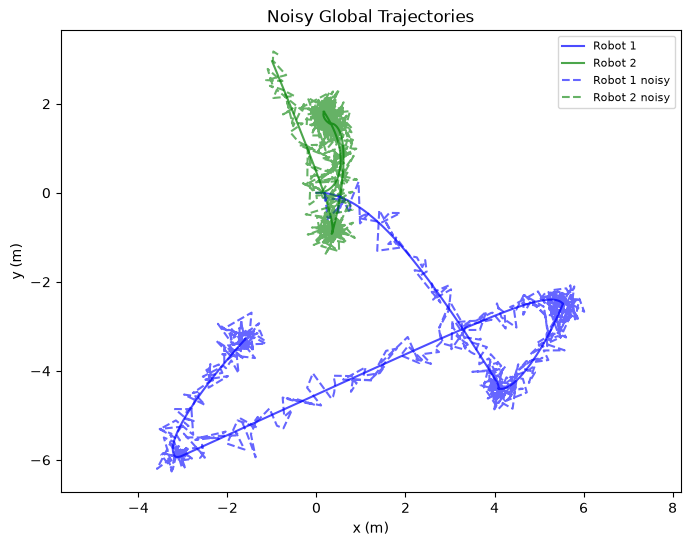

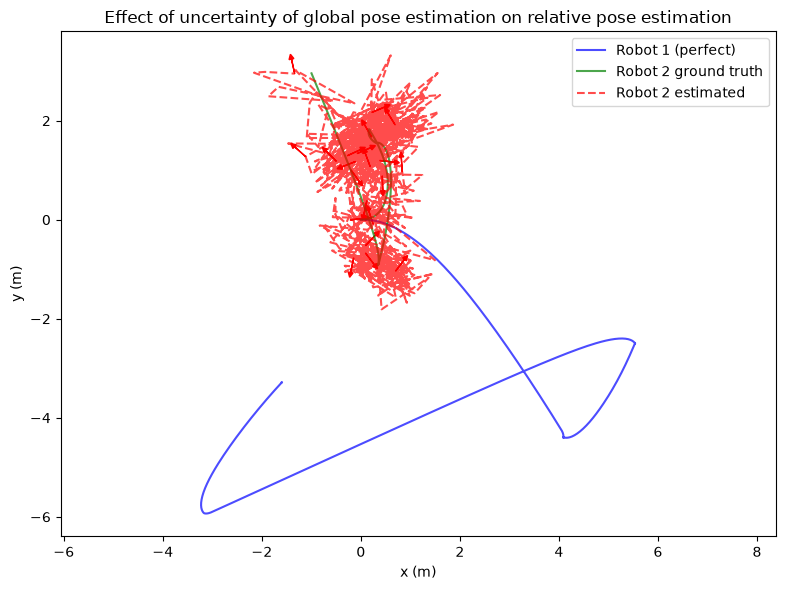

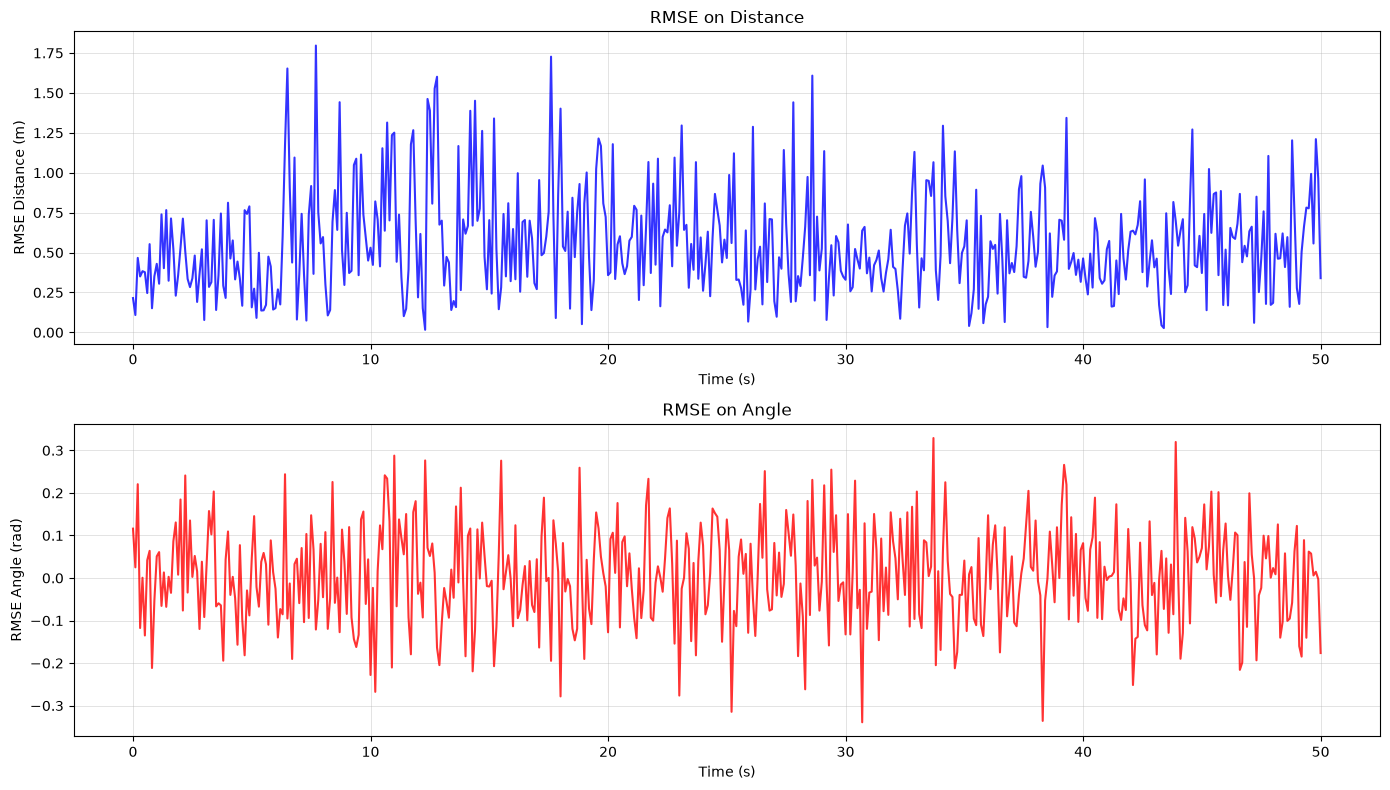

In [7]:
# Cell 8 continued: Visualize noisy case and RMSE analysis

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(poses_robot1[:, 0], poses_robot1[:, 1], 'b-', label='Robot 1', alpha=0.7)
ax.plot(poses_robot2[:, 0], poses_robot2[:, 1], 'g-', label='Robot 2', alpha=0.7)
ax.plot(poses_robot1_noisy[:, 0], poses_robot1_noisy[:, 1], 'b--', label='Robot 1 noisy', alpha=0.6)
ax.plot(poses_robot2_noisy[:, 0], poses_robot2_noisy[:, 1], 'g--', label='Robot 2 noisy', alpha=0.6)

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.axis('equal')
ax.legend(fontsize=8)
ax.set_title('Noisy Global Trajectories')

t = np.arange(len(relative_poses)) * traj_config.timestep

arrow_step = max(1, len(poses_robot1) // 20)

# Calculate Robot2 estimated location using Robot1 true pose + noisy relative pose
relative_poses_noisy_se2 = [SE2(p[0], p[1], p[2]) for p in relative_poses_noisy]
poses_robot2_estimated = np.zeros_like(poses_robot1)
for i in range(len(se2_robot1)):
    T_OR2_est = se2_robot1[i].compose(relative_poses_noisy_se2[i])
    poses_robot2_estimated[i, 0] = T_OR2_est.x()
    poses_robot2_estimated[i, 1] = T_OR2_est.y()
    poses_robot2_estimated[i, 2] = T_OR2_est.angle()

# Plot Robot2 estimation
fig2, ax2 = plt.subplots(1, 1, figsize=(8, 6))
ax2.plot(poses_robot1[:, 0], poses_robot1[:, 1], 'b-', label='Robot 1 (perfect)', alpha=0.7)
ax2.plot(poses_robot2[:, 0], poses_robot2[:, 1], 'g-', label='Robot 2 ground truth', alpha=0.7)
ax2.plot(poses_robot2_estimated[:, 0], poses_robot2_estimated[:, 1], 'r--', label='Robot 2 estimated', alpha=0.7)

for i in range(0, len(poses_robot2_estimated), arrow_step):
    x_i, y_i, theta_i = poses_robot2_estimated[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax2.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='r', ec='r')

ax2.set_xlabel('x (m)')
ax2.set_ylabel('y (m)')
ax2.axis('equal')
ax2.legend()
ax2.set_title('Effect of uncertainty of global pose estimation on relative pose estimation')

plt.tight_layout()
plt.show()

# Calculate RMSE metrics (per time instance)
pos_error = np.sqrt((relative_poses_noisy[:, 0] - relative_poses[:, 0])**2 + 
                   (relative_poses_noisy[:, 1] - relative_poses[:, 1])**2)
angle_error = relative_poses_noisy[:, 2] - relative_poses[:, 2]

# Plot RMSE over time
fig3, ax3 = plt.subplots(2, 1, figsize=(14, 8))

ax3[0].plot(t, pos_error, 'b-', alpha=0.8)
ax3[0].set_xlabel('Time (s)')
ax3[0].set_ylabel('RMSE Distance (m)')
ax3[0].set_title('RMSE on Distance')
ax3[0].grid(True)

angle_error = (angle_error + np.pi) % (2 * np.pi) - np.pi
ax3[1].plot(t, angle_error, 'r-', alpha=0.8)
ax3[1].set_xlabel('Time (s)')
ax3[1].set_ylabel('RMSE Angle (rad)')
ax3[1].set_title('RMSE on Angle')
ax3[1].grid(True)

plt.tight_layout()
plt.show()


# Cell 9: Noise propagation

The relative pose noise grows with distance and accumulates over time.